# Grover's search: quantum vs classical

This notebook walks through Grover's search algorithm in the notation of the FQC course and
shows the main results of the project. All logic lives in the `grover/` package; the notebook
only calls it. The figures in section 6 are produced by `scripts/run_experiments.py`.

**Bit order.** As in the course, qubit 0 is the top wire and the leftmost bit of every ket:
$|q_0 q_1 \dots q_{n-1}\rangle$. Qiskit prints bitstrings the other way round; the helper
`grover.quantum.to_course_order` converts them, and everything below is in course order.

In [1]:
import sys
from pathlib import Path

root = Path.cwd()
while not (root / "grover").is_dir():
    root = root.parent
sys.path.insert(0, str(root))

import math

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, Markdown, display
from qiskit import QuantumCircuit

from grover.circuits import diffuser, grover_circuit, optimal_iterations, theory_success, theta
from grover.classical import QueryCounter, classical_expected_queries, measure_classical, random_order_search
from grover.oracles import DEMO_FORMULA, formula_to_text, marked_oracle, multi_marked_oracle, sat_oracle
from grover.quantum import run_grover, runnable
from grover.statevector import grover_vector, simulate, to_ket

FIGURES = root / "results" / "figures"
SUMMARY = (root / "results" / "summary.md").read_text(encoding="utf-8")


def summary_section(number: int) -> str:
    # Return section `number` of results/summary.md (generated by run_experiments.py).
    start = SUMMARY.index(f"## {number}.")
    end = SUMMARY.find("\n## ", start + 1)
    return SUMMARY[start:] if end == -1 else SUMMARY[start:end]

## 1. The search problem and the classical cost

We are given a function $f:\{0,1\}^n \to \{0,1\}$ as a black box (an oracle, as in lecture 08),
with $f(x) = 1$ only for the marked item(s). There are $N = 2^n$ items and no structure to exploit:
the only way to learn about $f$ is to query it.

A classical computer can only query one item at a time. Checking items in a random order until the
marked one turns up costs $(N+1)/2$ queries on average and $N$ in the worst case. No classical
algorithm, deterministic or randomized, does better than order $N$.

The cell below counts real queries with `QueryCounter`, using the truth table of the same oracle
object that the quantum circuit uses.

In [2]:
n = 8
oracle = marked_oracle(n, "10110010")
counter = QueryCounter(oracle.f)
rng = np.random.default_rng(1)
found, calls = random_order_search(counter, n, rng)
print(f"one search: found {found} after {calls} queries (N = {2**n})")

stats = measure_classical(n, trials=2000, seed=1)
print(f"2000 searches with random marked items: average {stats.mean:.1f}, worst {stats.worst}")
print(f"theory: average (N+1)/2 = {classical_expected_queries(2**n):.1f}, worst N = {2**n}")

one search: found 10110010 after 55 queries (N = 256)


2000 searches with random marked items: average 126.7, worst 256
theory: average (N+1)/2 = 128.5, worst N = 256


## 2. The algorithm step by step

**Uniform superposition.** Start in $|0\rangle^{\otimes n}$ and apply $H^{\otimes n}$ (lecture 09):

$$|\psi_0\rangle = H^{\otimes n}|0\rangle^{\otimes n} = \frac{1}{\sqrt N}\sum_{x\in\{0,1\}^n} |x\rangle = |s\rangle .$$

**Oracle.** The bit oracle of lecture 08 is $U_f|x\rangle|y\rangle = |x\rangle|y \oplus f(x)\rangle$.
With the target qubit in $|-\rangle = (|0\rangle - |1\rangle)/\sqrt2$, phase kickback gives

$$U_f\,|x\rangle|-\rangle = (-1)^{f(x)}\,|x\rangle|-\rangle ,$$

so the target qubit can be dropped and the oracle acts as $O|x\rangle = (-1)^{f(x)}|x\rangle$: it
flips the sign of the marked items. For a single marked string $w$ this is built directly as
X gates where $w$ has a 0, a multi-controlled Z, and the same X gates again. The SAT oracle in
section 6 uses the $|-\rangle$ form explicitly.

**Diffuser.** $D = 2|s\rangle\langle s| - I = H^{\otimes n}\,(2|0\rangle\langle 0| - I)\,H^{\otimes n}$,
"inversion about the mean": every amplitude $a_x$ becomes $2\bar a - a_x$. In gates: H on all, X on
all, multi-controlled Z, X on all, H on all. That circuit equals $-(2|s\rangle\langle s| - I)$, a
global phase that cannot be measured.

**Grover iteration.** $G = D\,O$. After $k$ iterations, $|\psi_k\rangle = G^k|\psi_0\rangle$. Measure.

**Why it works.** Let $|w\rangle$ be the (normalised sum of) marked states, $|s'\rangle$ the
unmarked ones, and $\sin\theta = \sqrt{M/N}$. Then $|s\rangle = \cos\theta\,|s'\rangle + \sin\theta\,|w\rangle$.
The oracle reflects about $|s'\rangle$ and the diffuser reflects about $|s\rangle$; two reflections
make a rotation by $2\theta$, so

$$|\psi_k\rangle = \cos((2k+1)\theta)\,|s'\rangle + \sin((2k+1)\theta)\,|w\rangle,\qquad
P(\text{success}) = \sin^2((2k+1)\theta).$$

The project uses $k_{opt} = \lfloor (\pi/4)\sqrt{N/M} \rfloor$, which puts $(2k+1)\theta$ close to $\pi/2$.

## 3. The circuit for n = 3, one iteration

Marked item `101`. The barriers are labelled with the course states $|\psi_0\rangle$ (uniform
superposition) and $|\psi_1\rangle$ (after one iteration). First as blocks, then gate by gate.

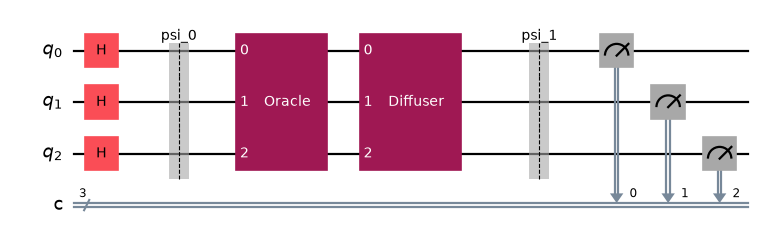

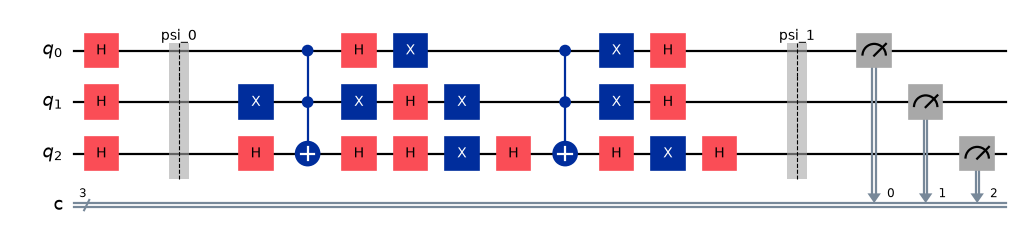

In [3]:
qc = grover_circuit(marked_oracle(3, "101"), 1)
display(qc.draw("mpl", fold=-1, scale=0.8))
display(runnable(qc).draw("mpl", fold=-1, scale=0.8))

## 4. Worked example: n = 2, marked item `11`

Here $N = 4$, $\sin\theta = 1/2$, so $\theta = \pi/6$ and one iteration gives
$(2\cdot 1+1)\theta = \pi/2$: the marked item is found with probability 1. The states below are
computed by our NumPy simulator gate by gate, in course bit order.

In [4]:
oracle = marked_oracle(2, "11")
h = QuantumCircuit(2)
h.h([0, 1])

psi_0 = simulate(h)
after_oracle = simulate(oracle.circuit, initial=psi_0)
psi_1 = simulate(diffuser(2), initial=after_oracle)

print("|psi_0>          =", to_ket(psi_0))
print("after the oracle =", to_ket(after_oracle))
print("|psi_1>          =", to_ket(psi_1), "  (global phase -1 from the diffuser circuit)")
print("P(11) =", round(abs(psi_1[3]) ** 2, 6), "   theory:", theory_success(4, 1, 1))

|psi_0>          = 0.5|00> + 0.5|01> + 0.5|10> + 0.5|11>
after the oracle = 0.5|00> + 0.5|01> + 0.5|10> - 0.5|11>
|psi_1>          = -1|11>   (global phase -1 from the diffuser circuit)
P(11) = 1.0    theory: 1.0


The oracle flips the sign of $|11\rangle$, which pulls the mean amplitude down to $1/4$. Inversion
about the mean maps the three amplitudes $1/2$ to $2\cdot\frac14 - \frac12 = 0$ and the amplitude
$-1/2$ to $2\cdot\frac14 + \frac12 = 1$.

## 5. The geometric picture

Each iteration rotates the state by $2\theta$ in the plane spanned by $|s'\rangle$ and $|w\rangle$.
The arrows below come from the vector-form simulator (n = 4, one marked item): the component along
$|w\rangle$ is the marked amplitude, the component along $|s'\rangle$ is the norm of the rest.
At $k_{opt}$ the state has rotated slightly past $|w\rangle$, which is why the success probability
is close to, but not exactly, 1.

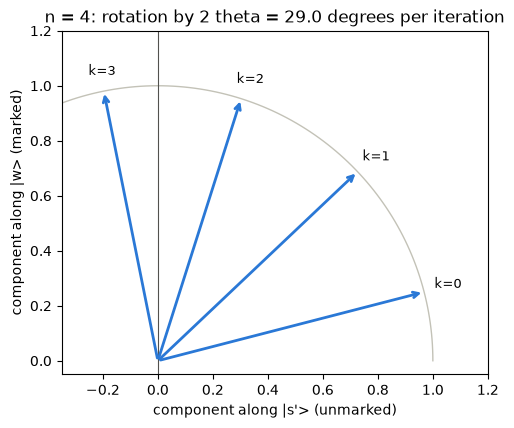

In [5]:
n, w = 4, 0b1001
N = 2**n
fig, ax = plt.subplots(figsize=(5.5, 5))
t = np.linspace(0, 0.62 * np.pi, 100)
ax.plot(np.cos(t), np.sin(t), color="#c3c2b7", lw=1)
for k in range(optimal_iterations(N) + 1):
    a = grover_vector(n, [w], k)
    x = np.sign(a[0]) * math.sqrt(1 - a[w] ** 2)
    y = a[w]
    ax.annotate("", xy=(x, y), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="#2a78d6", lw=2))
    ax.text(1.08 * x - 0.04, 1.06 * y, f"k={k}", fontsize=9)
ax.axvline(0, color="#52514e", lw=0.8)
ax.set_xlim(-0.35, 1.2)
ax.set_ylim(-0.05, 1.2)
ax.set_aspect("equal")
ax.set_xlabel("component along |s'> (unmarked)")
ax.set_ylabel("component along |w> (marked)")
ax.set_title(f"n = {n}: rotation by 2 theta = {math.degrees(2 * theta(N)):.1f} degrees per iteration")
plt.show()

## 6. Results

Every figure and table here is generated by `scripts/run_experiments.py` with fixed seeds.

### 6.1 It works

In [6]:
display(Markdown(summary_section(1)))

## 1. Correctness (k_opt = floor((pi/4) sqrt(N)))

| n | N | marked | k_opt | theory P | NumPy P | Aer P | top result correct | every item found (n <= 4) |
|---|---|---|---|---|---|---|---|---|
| 2 | 4 | `11` | 1 | 1.0000 | 1.0000 | 1.000 | yes | yes (min P 1.000) |
| 3 | 8 | `101` | 2 | 0.9453 | 0.9453 | 0.951 | yes | yes (min P 0.936) |
| 4 | 16 | `1010` | 3 | 0.9613 | 0.9613 | 0.961 | yes | yes (min P 0.955) |
| 5 | 32 | `11100` | 4 | 0.9992 | 0.9992 | 1.000 | yes | - |
| 6 | 64 | `100101` | 6 | 0.9966 | 0.9966 | 0.998 | yes | - |
| 7 | 128 | `1100011` | 8 | 0.9956 | 0.9956 | 0.996 | yes | - |
| 8 | 256 | `11010101` | 12 | 0.9999 | 0.9999 | 1.000 | yes | - |
| 9 | 512 | `001110011` | 17 | 0.9994 | 0.9994 | 1.000 | yes | - |
| 10 | 1024 | `0000111000` | 25 | 0.9995 | 0.9995 | 0.999 | yes | - |


For every $n$ the most likely measurement is the marked item, and the simulated success
probabilities (our NumPy simulator and Qiskit Aer) agree with $\sin^2((2k+1)\theta)$ within shot noise.
For small $n$ every possible marked item was tried.

### 6.2 Queries vs N

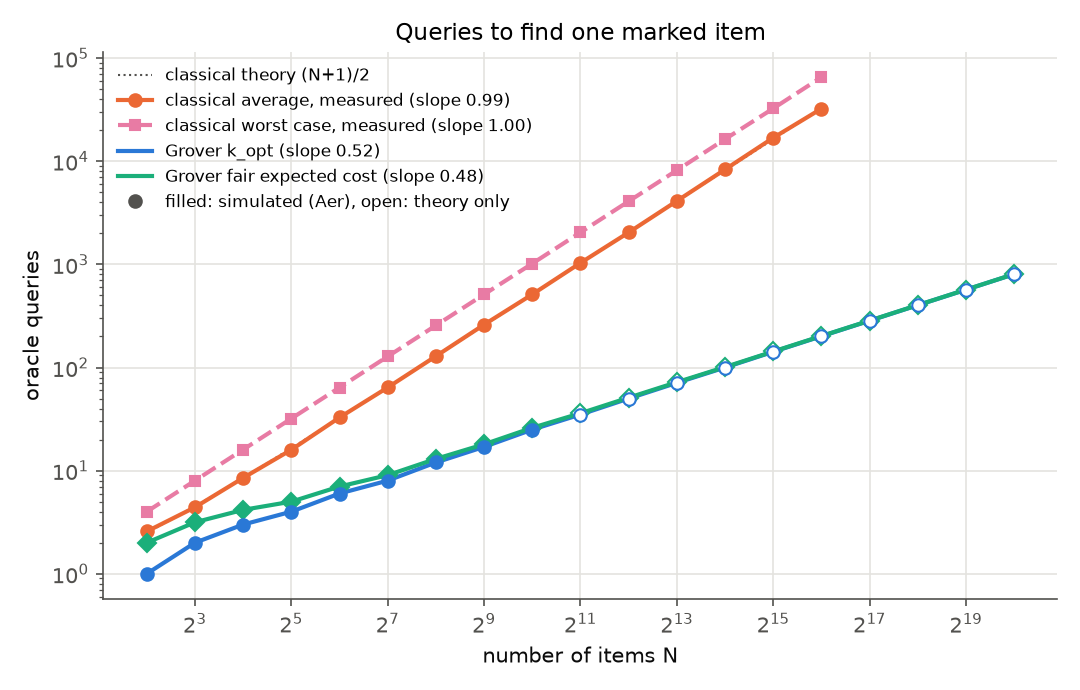

## 2. Queries vs N

Fitted log-log slopes (queries ~ N^slope), classical for n = 2..16 with 500 searches per n, Grover for n = 2..20:

| quantity | slope |
|---|---|
| classical average queries (measured) | 0.987 |
| classical worst case (measured) | 1.000 |
| Grover k_opt (oracle calls) | 0.517 |
| Grover fair expected cost | 0.479 |


In [7]:
display(Image(filename=str(FIGURES / "queries_vs_N.png")))
display(Markdown(summary_section(2)))

On log-log axes a power law $N^a$ is a straight line of slope $a$. The classical counts, measured by
counting real oracle calls, have slope close to 1; Grover's query count has slope close to 1/2.
The floor in $k_{opt}$ makes the small-$N$ points ragged, which moves the fitted Grover slopes a
little away from exactly 1/2.

### 6.3 A fair count

In [8]:
display(Markdown(summary_section(3)))

## 3. Fair comparison

| n | N | classical expected (N+1)/2 | classical measured avg | classical measured worst | Grover k_opt | Grover P | Grover fair cost (k+1)/P | speedup | Grover P from |
|---|---|---|---|---|---|---|---|---|---|
| 2 | 4 | 2.5 | 2.6 | 4 | 1 | 1.0000 | 2.00 | 1.2 | Aer |
| 4 | 16 | 8.5 | 8.5 | 16 | 3 | 0.9605 | 4.16 | 2.0 | Aer |
| 6 | 64 | 32.5 | 32.8 | 64 | 6 | 0.9980 | 7.01 | 4.6 | Aer |
| 8 | 256 | 128.5 | 128.8 | 256 | 12 | 0.9998 | 13.00 | 9.9 | Aer |
| 10 | 1024 | 512.5 | 512.1 | 1019 | 25 | 0.9985 | 26.04 | 19.7 | Aer |
| 12 | 4096 | 2048.5 | 2040.5 | 4093 | 50 | 0.9999 | 51.00 | 40.2 | theory |
| 14 | 16384 | 8192.5 | 8331.5 | 16384 | 100 | 1.0000 | 101.00 | 81.1 | theory |
| 16 | 65536 | 32768.5 | 32370.3 | 65331 | 201 | 1.0000 | 202.00 | 162.2 | theory |
| 18 | 262144 | 131072.5 | - | - | 402 | 1.0000 | 403.00 | 325.2 | theory |
| 20 | 1048576 | 524288.5 | - | - | 804 | 1.0000 | 805.00 | 651.3 | theory |


Grover succeeds with probability $P < 1$, so a fair cost repeats it until it succeeds and checks
each candidate with one classical query: $(k_{opt}+1)/P$ expected queries. That is still order
$\sqrt N$, so the speedup column grows like $\sqrt N$: the advantage is **quadratic**, not
exponential. Exponential speedups (like Shor's) need problem structure that unstructured search
does not have, and Grover is provably optimal for this problem.

### 6.4 Iterations matter

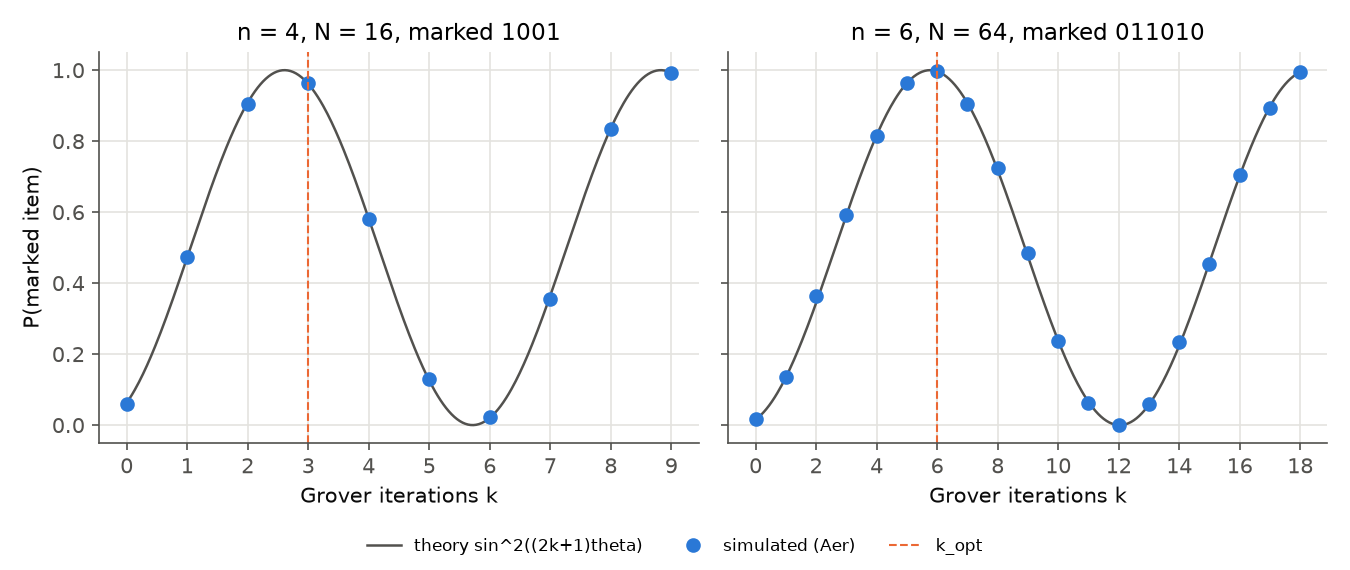

## 4. Success vs iterations

| n | k_opt | Aer P at k_opt | 2 k_opt | Aer P at 2 k_opt | 3 k_opt | Aer P at 3 k_opt | largest gap between Aer and theory over all k |
|---|---|---|---|---|---|---|---|
| 4 | 3 | 0.964 | 6 | 0.022 | 9 | 0.993 | 0.010 |
| 6 | 6 | 0.998 | 12 | 0.000 | 18 | 0.995 | 0.021 |


In [9]:
display(Image(filename=str(FIGURES / "success_vs_iterations.png")))
display(Markdown(summary_section(4)))

The success probability oscillates. Stopping at $2k_{opt}$ rotates the state past $|w\rangle$
back to almost nothing, so too many iterations is as bad as too few. You must know (or estimate)
$M$ to choose $k$.

### 6.5 More than one answer

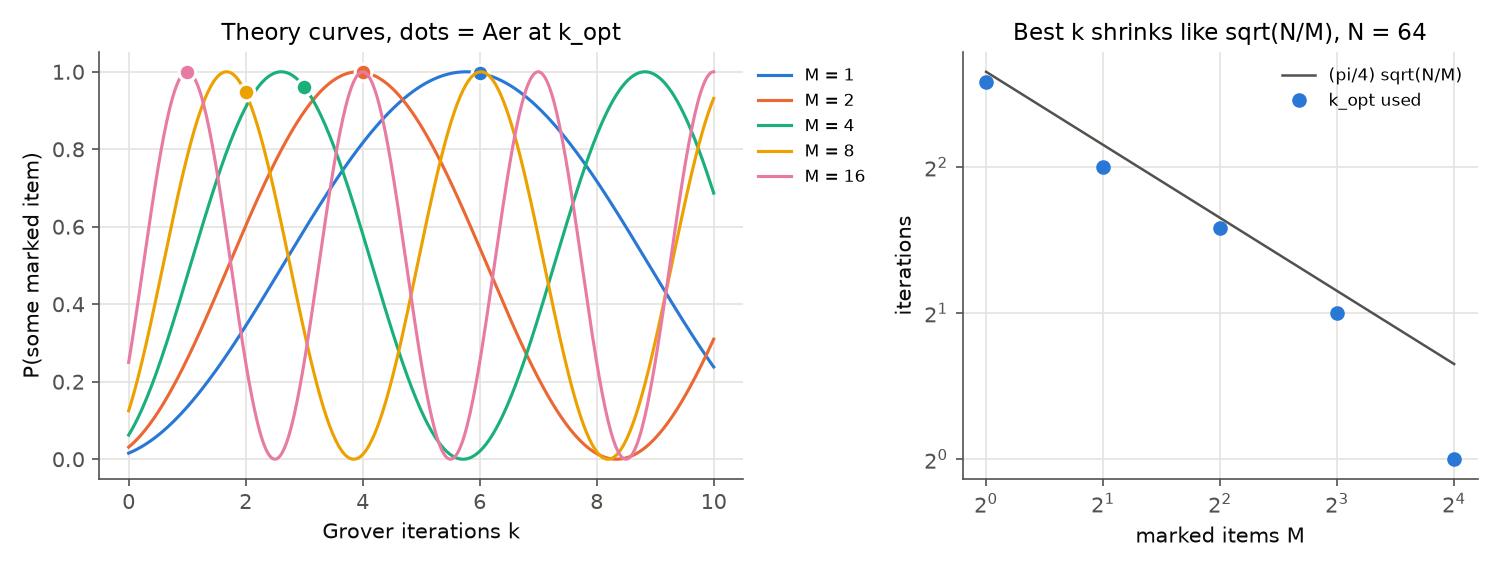

## 5. Multiple marked items (n = 6, N = 64)

| M | (pi/4) sqrt(N/M) | k_opt | theory P | Aer P | classical expected (N+1)/(M+1) |
|---|---|---|---|---|---|
| 1 | 6.28 | 6 | 0.9966 | 0.997 | 32.50 |
| 2 | 4.44 | 4 | 0.9992 | 1.000 | 21.67 |
| 4 | 3.14 | 3 | 0.9613 | 0.961 | 13.00 |
| 8 | 2.22 | 2 | 0.9453 | 0.949 | 7.22 |
| 16 | 1.57 | 1 | 1.0000 | 1.000 | 3.82 |


In [10]:
display(Image(filename=str(FIGURES / "multiple_marked.png")))
display(Markdown(summary_section(5)))

With $M$ marked items $\sin\theta = \sqrt{M/N}$ is larger, the rotation is faster, and the best
number of iterations shrinks like $\sqrt{N/M}$ (Boyer, Brassard, Hoyer and Tapp).

### 6.6 A real search problem: SAT

The usual objection is that "the oracle already knows the answer". Here it does not: the oracle
evaluates a CNF formula clause by clause with Toffoli and multi-controlled X gates on ancilla
qubits, writes the result onto a $|-\rangle$ qubit (phase kickback, as in lecture 08), and
uncomputes the ancillas. The satisfying assignments are found by brute force only to check the answer.

## 6. SAT demo

- Formula: `(x1 OR x2 OR x3) AND (NOT x1 OR NOT x3) AND (x1 OR NOT x2) AND (x3 OR x4) AND (x2 OR NOT x4)`
- Satisfying assignments by brute force (x1 x2 x3 x4): `0010`, `1101`
- Circuit: 4 variable qubits, 5 clause ancillas, 1 output qubit in |->, 10 qubits in total
- Grover with M = 2, N = 16: k_opt = 2, theory P = 0.9453, Aer P = 0.946
- Three most frequent results: `0010` (0.480), `1101` (0.465), `1011` (0.006)


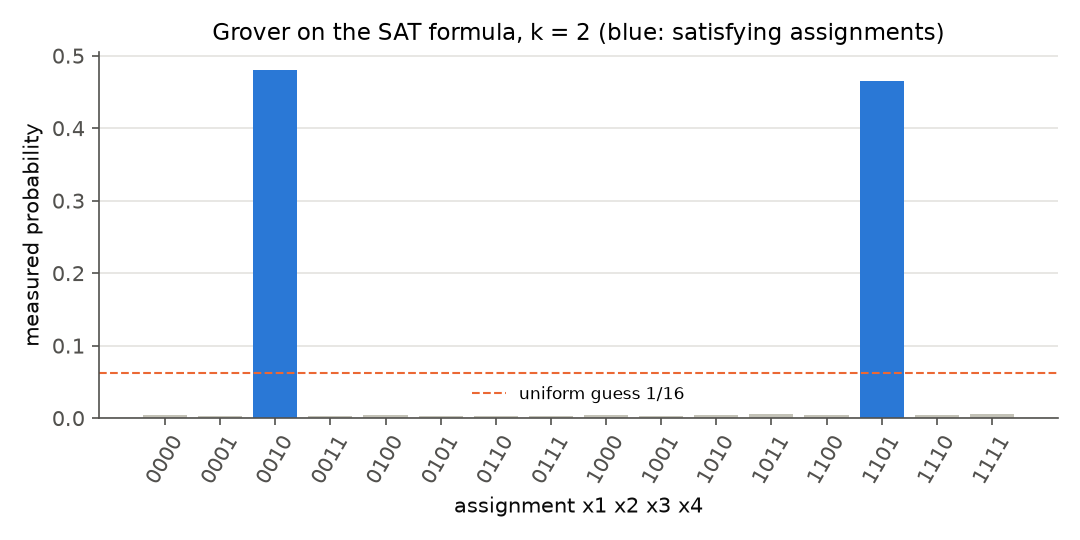

In [11]:
display(Markdown(summary_section(6)))
display(Image(filename=str(FIGURES / "sat_histogram.png")))

Grover amplifies exactly the satisfying assignments, using the formula alone. Building this oracle
needs only the formula, never its solutions.

### 6.7 Noise

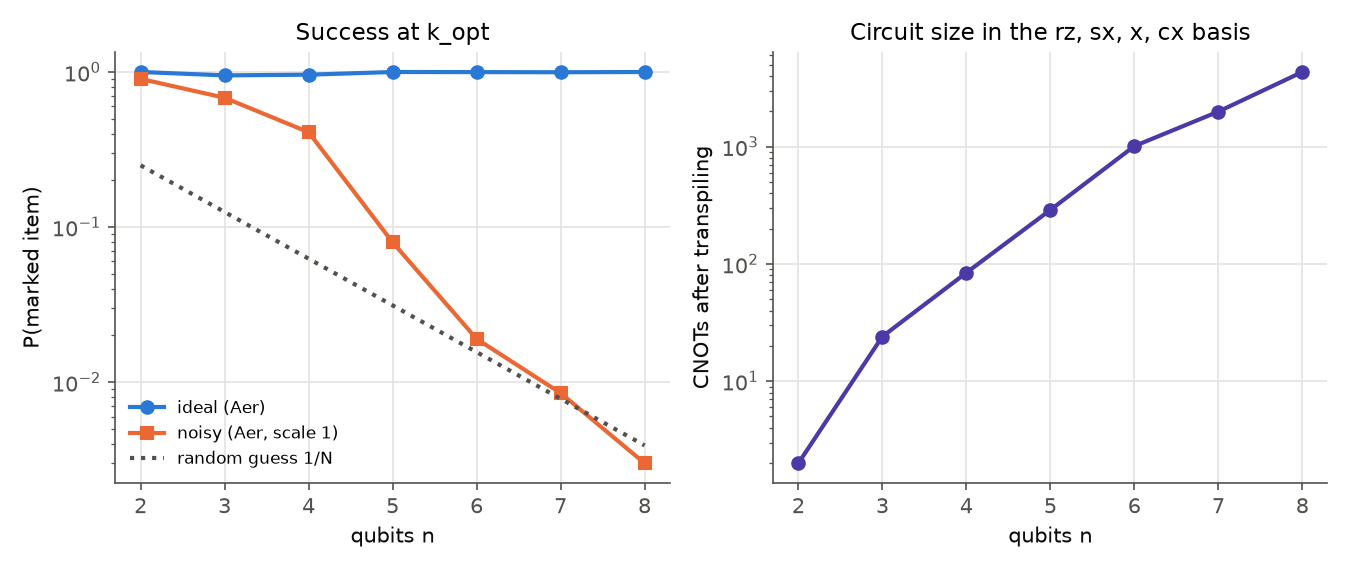

## 7. Noise vs n (scale 1)

| n | N | k_opt | ideal P (Aer) | noisy P (Aer) | random guess 1/N | CNOTs after transpile |
|---|---|---|---|---|---|---|
| 2 | 4 | 1 | 1.000 | 0.902 | 0.250 | 2 |
| 3 | 8 | 2 | 0.951 | 0.682 | 0.125 | 24 |
| 4 | 16 | 3 | 0.961 | 0.409 | 0.062 | 84 |
| 5 | 32 | 4 | 1.000 | 0.080 | 0.031 | 288 |
| 6 | 64 | 6 | 0.998 | 0.019 | 0.016 | 1008 |
| 7 | 128 | 8 | 0.996 | 0.009 | 0.008 | 1984 |
| 8 | 256 | 12 | 1.000 | 0.003 | 0.004 | 4320 |

From n = 6 on (1008 CNOTs) the noisy success probability is below twice the random-guess level 1/N.


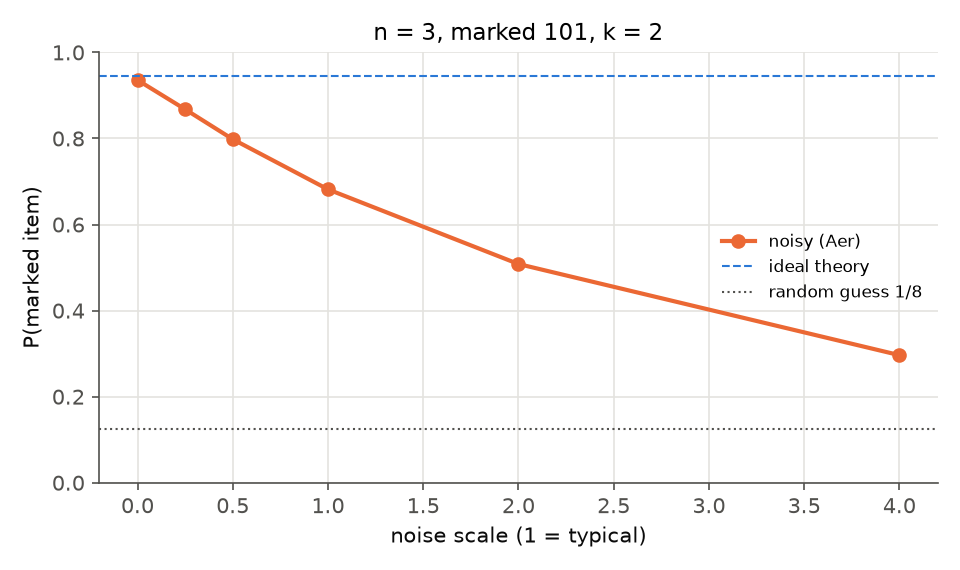

## 8. Noise vs level

n = 3, marked `101`, k = 2, ideal theory P = 0.9453, 24 CNOTs after transpiling.

| noise scale | P(marked item) |
|---|---|
| 0 | 0.936 |
| 0.25 | 0.868 |
| 0.5 | 0.798 |
| 1 | 0.682 |
| 2 | 0.508 |
| 4 | 0.296 |


In [12]:
display(Image(filename=str(FIGURES / "noise_vs_n.png")))
display(Markdown(summary_section(7)))
display(Image(filename=str(FIGURES / "noise_vs_level.png")))
display(Markdown(summary_section(8)))

Real hardware has no multi-controlled gates. After transpiling to `rz, sx, x, cx` the CNOT count
grows quickly with $n$, and with typical error rates (every basis gate and every readout noisy)
the success rate collapses towards random guessing $1/N$. Even at $n = 3$ the success probability
falls steadily as the noise level grows. Grover's advantage at scale needs error-corrected hardware.

### 6.8 Why simulation is not a speedup

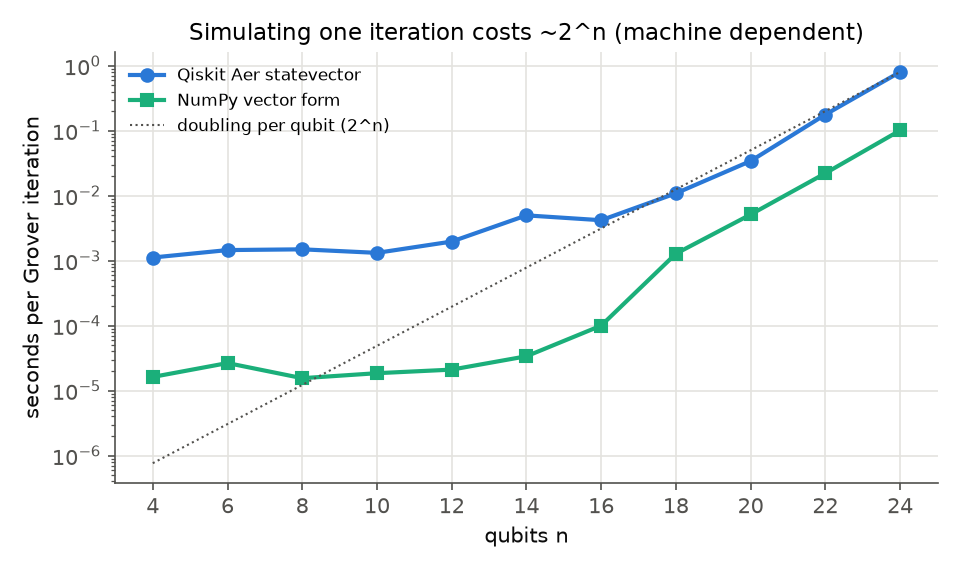

## 9. Simulation cost (machine dependent)

Time for one Grover iteration on the full 2^n state, best of several runs. Fitted growth per added
qubit for n >= 16: Aer x1.94, NumPy x2.30.

| n | Aer s / iteration | NumPy s / iteration | k_opt (iterations a full run needs) |
|---|---|---|---|
| 4 | 0.00111 | 0.00002 | 3 |
| 6 | 0.00145 | 0.00003 | 6 |
| 8 | 0.00149 | 0.00002 | 12 |
| 10 | 0.00132 | 0.00002 | 25 |
| 12 | 0.00196 | 0.00002 | 50 |
| 14 | 0.00497 | 0.00003 | 100 |
| 16 | 0.00418 | 0.00010 | 201 |
| 18 | 0.01085 | 0.00128 | 402 |
| 20 | 0.03408 | 0.00512 | 804 |
| 22 | 0.17686 | 0.02211 | 1608 |
| 24 | 0.79957 | 0.10092 | 3216 |


In [13]:
display(Image(filename=str(FIGURES / "simulation_cost.png")))
display(Markdown(summary_section(9)))

A classical simulator stores all $2^n$ amplitudes, so even one iteration costs time proportional to
$2^n$ (and a full run needs about $\sqrt{2^n}$ iterations). The simulation is a classical
computation; the quantum advantage is counted in **oracle queries**, not in wall-clock time on a laptop.

## 7. Conclusion

- **What the advantage is:** Grover finds a marked item among $N$ unsorted items with about
  $(\pi/4)\sqrt{N/M}$ oracle queries, against about $N/2$ classically. Measured by counting real
  oracle calls, the log-log slopes are close to 1/2 and 1.
- **What it is not:** it is a quadratic speedup in queries, not an exponential one, and it does not
  make classical simulation fast: the simulator's cost grows like $2^n$.
- **Details that matter:** too many iterations undo the progress; $M$ marked items need fewer
  iterations; the oracle can be a real checker (SAT) rather than a lookup of the answer.
- **What noise does:** the multi-controlled gates become hundreds or thousands of CNOTs, and with
  realistic error rates the success rate falls to the random-guess level after a few qubits.

## 8. Try it yourself

Change `n`, `marked` and `k` and run the cell. Leave `k = None` to use $k_{opt}$.

N = 32, M = 2, k = 3, oracle calls counted from the circuit = 3
success probability: simulated 0.957, theory 0.961
most likely result: 00011 (marked: True)


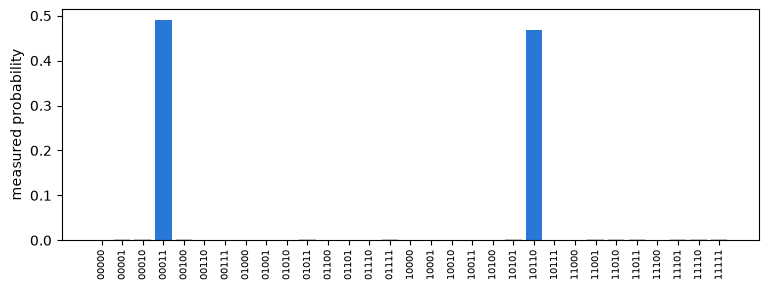

In [14]:
n = 5
marked = ["10110", "00011"]
k = None

oracle = multi_marked_oracle(n, marked)
k = optimal_iterations(oracle.N, oracle.M) if k is None else k
result = run_grover(oracle, k, shots=4000, seed=1)
print(f"N = {oracle.N}, M = {oracle.M}, k = {k}, oracle calls counted from the circuit = {result.oracle_calls}")
print(f"success probability: simulated {result.success_probability:.3f}, theory {theory_success(oracle.N, oracle.M, k):.3f}")
print(f"most likely result: {result.most_likely} (marked: {result.found})")

xs = sorted(result.counts)
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(xs, [result.counts[x] / result.shots for x in xs],
       color=["#2a78d6" if x in oracle.marked else "#c3c2b7" for x in xs])
ax.set_ylabel("measured probability")
ax.tick_params(axis="x", rotation=90, labelsize=7)
plt.show()